In [1]:
# COMMIT 1: Project Setup and Dataset Exploration
# Implementation Scope:
# - Central configuration, global seeding and automatic device selection.
# - Zip-based image archive that reads train and test images without extracting them.
# - Label distribution, class imbalance ratio, image integrity and dimension profiling.
# - Correlation heatmap, file-size scatter plot and per-class sample grid.

# import standard libraries
import io
import math
import os
import random
import threading
import time
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path, PurePosixPath

# import third-party libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from torchvision import models

# setting up the configuration dictionary
CONFIG = {
    "labels_csv": Path("./train_labels.csv"),
    "train_archives": (Path("./train_part1.zip"), Path("./train_part2.zip")),
    "test_archives": (Path("./test.zip"),),
    "cache_dir": Path("./outputs/cache"),
    "checkpoint_dir": Path("./outputs/checkpoints"),
    "history_dir": Path("./outputs/history"),
    "image_size": (224, 224),
    "image_extensions": {".jpg", ".jpeg", ".png"},
    "classes": (
        "CatEye", "DogEye", "CatFace", "DogFace",
        "CatMouth", "DogMouth", "CatNose", "DogNose",
    ),
    "imagenet_mean": (0.485, 0.456, 0.406), # mean and std values for normalization based on ImageNet dataset
    "imagenet_std": (0.229, 0.224, 0.225), 
    "seed": 42,
    "val_fraction": 0.2, # fraction of the training data to be used for validation
    "profile_sample_size": 3000, # number of samples to profile for class distribution and other statistics
    "batch_size": 64, # number of samples per batch during training and evaluation
    "train_batch_size": 256, 
    "eval_batch_size": 1024, 
    "weight_decay": 1e-2, # weight decay (L2 regularization) factor for optimizer
    "eta_min": 1e-6, # minimum learning rate for the learning rate scheduler
    "dropout": 0.4, # dropout rate for regularization in the model
    "head_dropout": 0.3, # dropout rate for the classification head in the model
    "backbone": "convnext_tiny", # backbone architecture to be used for feature extraction in the model
    "device": torch.device(
        "cuda" if torch.cuda.is_available()
        else "mps" if torch.backends.mps.is_available()
        else "cpu"
    ),
}
# number of classes in the dataset is determined by the length of the "classes" tuple in the CONFIG dictionary
CONFIG["num_classes"] = len(CONFIG["classes"])
class_to_idx = {name: idx for idx, name in enumerate(CONFIG["classes"])}

# setting the random seed for reproducibility across various libraries and frameworks
def seed_everything(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# setting the random seed for reproducibility
seed_everything(CONFIG["seed"])
sns.set_theme(style="whitegrid", context="notebook")
print(f"seed={CONFIG['seed']} | device={CONFIG['device']} | target size={CONFIG['image_size']}")

seed=42 | device=cuda | target size=(224, 224)


In [2]:
# defining the ImageArchive class to handle image data stored in zip archives
class ImageArchive:
    def __init__(self, zip_paths, extensions):
        self.zip_paths = tuple(Path(p) for p in zip_paths)
        self.extensions = frozenset(e.lower() for e in extensions)
        self.members = {}
        for zip_path in self.zip_paths:
            with zipfile.ZipFile(zip_path) as archive:
                for info in archive.infolist():
                    member = PurePosixPath(info.filename)
                    is_junk = info.is_dir() or member.parts[0] == "__MACOSX" or member.name.startswith("._")
                    if is_junk or member.suffix.lower() not in self.extensions:
                        continue
                    if member.stem in self.members:
                        raise ValueError(f"duplicate image id {member.stem} in {zip_path}")
                    self.members[member.stem] = (zip_path, info.filename, info.CRC, info.file_size)
        self.ids = sorted(self.members)
        self._local = threading.local()
    # defining the length of the ImageArchive object as the number of unique image ids
    def __len__(self):
        return len(self.members)
    # defining the containment check for image ids in the ImageArchive object
    def __contains__(self, image_id):
        return image_id in self.members
    # defining the item retrieval for image ids in the ImageArchive object
    def _handle(self, zip_path):
        files = getattr(self._local, "files", None)
        if files is None:
            files = self._local.files = {}
        if zip_path not in files:
            files[zip_path] = zipfile.ZipFile(zip_path)
        return files[zip_path]
    # defining the method to read bytes of an image given its id
    def read_bytes(self, image_id):
        zip_path, name, _, _ = self.members[image_id]
        return self._handle(zip_path).read(name)
    # defining the method to open an image in RGB format given its id
    def open_rgb(self, image_id):
        with Image.open(io.BytesIO(self.read_bytes(image_id))) as img:
            return img.convert("RGB")
    # defining the method to get the file size of an image given its id
    def file_size(self, image_id):
        return self.members[image_id][3]
    # defining the method to get a digest string for an image given its id, which includes its CRC and file size
    def digest(self, image_id):
        _, _, crc, size = self.members[image_id]
        return f"{crc:08x}-{size}"

# setting up the training and testing image archives using the ImageArchive class
train_archive = ImageArchive(CONFIG["train_archives"], CONFIG["image_extensions"])
test_archive = ImageArchive(CONFIG["test_archives"], CONFIG["image_extensions"])
print(f"train archive: {len(train_archive):,} images | test archive: {len(test_archive):,} images")

train archive: 63,660 images | test archive: 29,443 images


Total labelled samples: 63,660

          count  percent
class                   
CatEye    13884    21.81
DogEye    11580    18.19
CatFace    6942    10.90
DogFace    5790     9.10
CatMouth   6942    10.90
DogMouth   5790     9.10
CatNose    6942    10.90
DogNose    5790     9.10

Imbalance ratio (majority/minority): 2.398:1 (CatEye = 13,884, DogFace = 5,790)


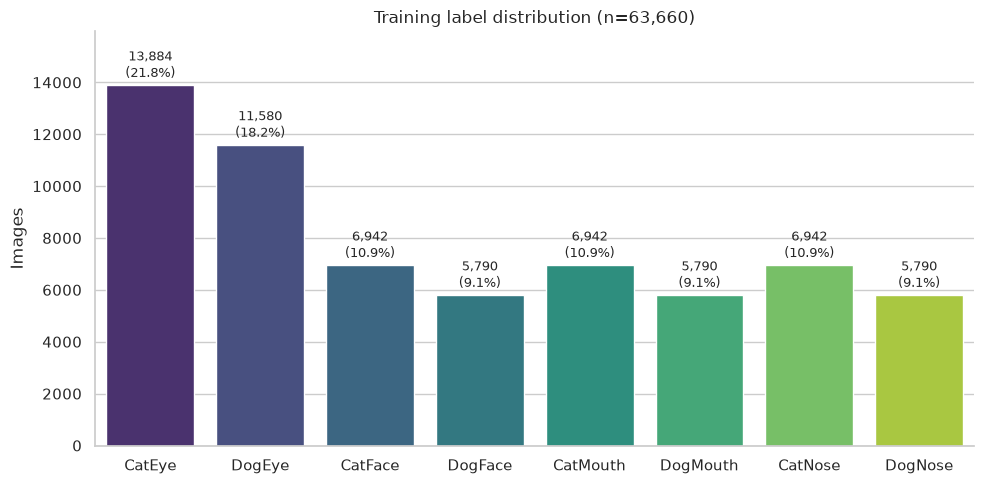

In [3]:
labels = pd.read_csv(CONFIG["labels_csv"], dtype={"image_id": str}) # reading the labels CSV file into a pandas DataFrame
classes = CONFIG["classes"] # defining the expected classes for the dataset 

unexpected = set(labels["class"]) - set(classes) # checking for any unexpected labels in the dataset
assert not unexpected, f"Unexpected labels: {sorted(unexpected)}" # checking for duplicate image_id values in the labels DataFrame
assert labels["image_id"].is_unique, "Duplicate image_id values in labels" # checking for any null values in the 'class' column of the labels DataFrame
assert labels["class"].notna().all(), "Null labels present" # checking for any null values in the 'image_id' column of the labels DataFrame

distribution = labels["class"].value_counts().reindex(classes).rename("count").to_frame() # creating a DataFrame to hold the count of each class in the dataset
distribution["percent"] = distribution["count"] / distribution["count"].sum() * 100 # calculating the percentage of each class in the dataset

print(f"Total labelled samples: {len(labels):,}\n")
# displaying the distribution of classes in the dataset, rounded to two decimal places
print(distribution.assign(percent=distribution["percent"].round(2)).to_string()) 
majority_class, minority_class = distribution["count"].idxmax(), distribution["count"].idxmin() # identifying the majority and minority classes in the dataset
imbalance_ratio = distribution["count"].max() / distribution["count"].min() # calculating the imbalance ratio between the majority and minority classes in the dataset
print(f"\nImbalance ratio (majority/minority): {imbalance_ratio:.3f}:1 " 
      f"({majority_class} = {distribution['count'].max():,}, {minority_class} = {distribution['count'].min():,})") # displaying the imbalance ratio

# visualizing the distribution of classes in the dataset using a bar plot
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=distribution.reset_index(names="class"),
    x="class", y="count", hue="class", order=classes,
    palette="viridis", legend=False, ax=ax,
)
# annotating the bar plot with the count and percentage of each class
for position, (_, row) in enumerate(distribution.iterrows()):
    ax.annotate(
        f"{int(row['count']):,}\n({row['percent']:.1f}%)",
        (position, row["count"]), xytext=(0, 3), textcoords="offset points",
        ha="center", va="bottom", fontsize=9,
    )

# setting the y-axis limits, labels, and title for the bar plot
ax.set_ylim(0, distribution["count"].max() * 1.15)
ax.set_xlabel("")
ax.set_ylabel("Images")
ax.set_title(f"Training label distribution (n={len(labels):,})")
sns.despine(ax=ax) 
fig.tight_layout()
plt.show()

Train images in archives: 63,660 | labelled: 63,660 | labels without image: 0 | images without label: 0
Test images in archive: 29,443

--- train: 3,000 sampled, 0 corrupted ---
                 min        max      mean  median
width           4.00     978.00    111.26    84.0
height          4.00     989.00    107.46    80.0
aspect_ratio    0.47       4.25      1.06     1.0
bytes         673.00  317708.00  10060.10  4306.0
channel modes: {'RGB': 3000}
non-square (aspect ratio outside 0.95-1.05): 30.6%
upscaled to 224 (short side < 224): 93.1%
downscaled to 224 (long side > 224): 9.8%

--- test: 3,000 sampled, 0 corrupted ---
                 min        max      mean  median
width           8.00    1442.00    113.71    82.5
height          9.00    1443.00    110.32    80.0
aspect_ratio    0.44       4.44      1.07     1.0
bytes         693.00  520442.00  10611.03  4247.5
channel modes: {'RGB': 3000}
non-square (aspect ratio outside 0.95-1.05): 55.3%
upscaled to 224 (short side < 224): 

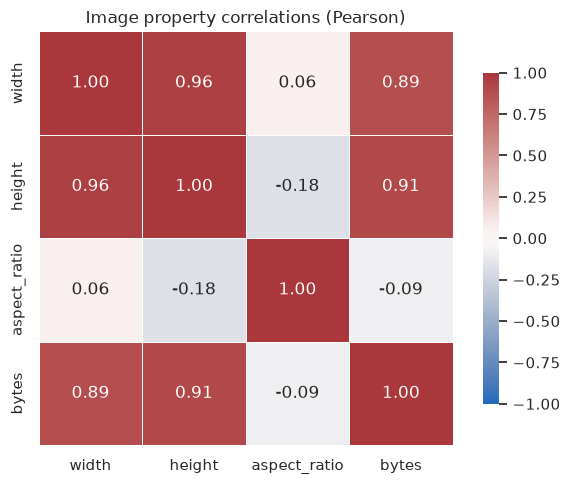

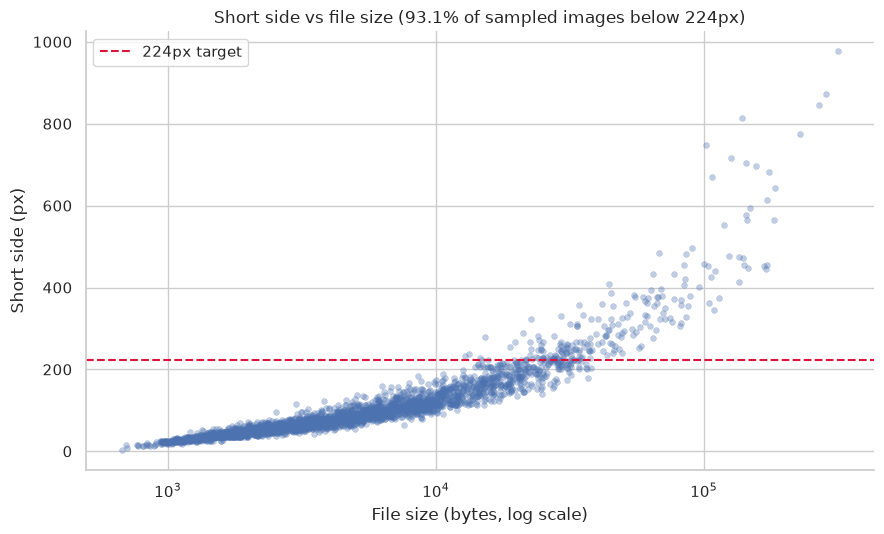

In [4]:

# defining a function to profile images by sampling and collecting their properties
def profile_images(archive, sample_size, seed):
    sample = random.Random(seed).sample(archive.ids, min(sample_size, len(archive)))
    records, corrupted = [], []
    for image_id in sample:
        try:
            data = archive.read_bytes(image_id)
            with Image.open(io.BytesIO(data)) as img:
                img.verify()
            with Image.open(io.BytesIO(data)) as img:
                img.load()
                records.append({
                    "file": image_id,
                    "width": img.width,
                    "height": img.height,
                    "channels": len(img.getbands()),
                    "mode": img.mode,
                    "bytes": archive.file_size(image_id),
                })
        except Exception as exc:
            corrupted.append((image_id, repr(exc))) # appending the name of the corrupted file and the exception message to the corrupted list
    frame = pd.DataFrame(records) # creating a DataFrame from the records list to hold the properties of the sampled images
    frame["aspect_ratio"] = frame["width"] / frame["height"] # calculating the aspect ratio of each image and adding it as a new column in the DataFrame
    return frame, corrupted # returning the DataFrame containing the properties of the sampled images and the list of corrupted files

# defining a function to report the profile of images, including statistics and information about corrupted files
def report_profile(name, frame, corrupted, target):
    stats = frame[["width", "height", "aspect_ratio", "bytes"]].agg(["min", "max", "mean", "median"]).T
    short_side = frame[["width", "height"]].min(axis=1)
    long_side = frame[["width", "height"]].max(axis=1)
    print(f"--- {name}: {len(frame):,} sampled, {len(corrupted)} corrupted ---")
    print(stats.round(2).to_string())
    print("channel modes:", frame["mode"].value_counts().to_dict())
    print(f"non-square (aspect ratio outside 0.95-1.05): {((frame['aspect_ratio'] < 0.95) | (frame['aspect_ratio'] > 1.05)).mean():.1%}")
    print(f"upscaled to {target} (short side < {target}): {(short_side < target).mean():.1%}")
    print(f"downscaled to {target} (long side > {target}): {(long_side > target).mean():.1%}")
    for file_name, error in corrupted[:5]:
        print(f"  corrupted: {file_name} -> {error}")
    print()


label_ids = set(labels["image_id"]) # creating a set of image IDs from the labels DataFrame for comparison with the files on disk
archive_ids = set(train_archive.ids) # creating a set of image IDs from the training archive for comparison with the labels DataFrame
# printing the counts of training and test images on disk, labelled images, and any discrepancies between the labels and files
print(f"Train images in archives: {len(train_archive):,} | labelled: {len(label_ids):,} | "
      f"labels without image: {len(label_ids - archive_ids):,} | images without label: {len(archive_ids - label_ids):,}")
print(f"Test images in archive: {len(test_archive):,}\n")
assert not label_ids - archive_ids, "Some labelled images are missing from the train archives" # asserting that all labelled images are present in the training folder

# profiling the training and test images, and reporting their properties and any corrupted files
target = CONFIG["image_size"][0]
train_profile, train_corrupted = profile_images(train_archive, CONFIG["profile_sample_size"], CONFIG["seed"])
test_profile, test_corrupted = profile_images(test_archive, CONFIG["profile_sample_size"], CONFIG["seed"])
report_profile("train", train_profile, train_corrupted, target) # reporting the profile of the training images, including statistics and information about corrupted files
report_profile("test", test_profile, test_corrupted, target) # reporting the profile of the test images, including statistics and information about corrupted files

# added 2 more exploratory data analysis visualizations to the notebook, including a heatmap of the Pearson correlation matrix for image properties and a scatter plot showing the relationship between file size and short side of the images in the training profile DataFrame
# adding a new column to the training profile DataFrame to hold the short side of each image, which is the minimum of its width and height
profile = train_profile.assign(short_side=train_profile[["width", "height"]].min(axis=1))

# calculating the Pearson correlation matrix for the width, height, aspect ratio, and bytes columns of the training profile DataFrame
correlation = profile[["width", "height", "aspect_ratio", "bytes"]].corr(method="pearson")
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
    correlation, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax,
) # creating a heatmap to visualize the Pearson correlation matrix, with annotations, color mapping, and formatting options
ax.set_title("Image property correlations (Pearson)")
fig.tight_layout()
plt.show()

# visualizing the relationship between file size and short side of the images in the training profile DataFrame using a scatter plot
upscaled_share = (profile["short_side"] < target).mean()
fig, ax = plt.subplots(figsize=(9, 5.5)) # creating a new figure and axis for the scatter plot with specified dimensions
sns.scatterplot(data=profile, x="bytes", y="short_side", alpha=0.35, s=18, edgecolor=None, ax=ax)
ax.axhline(target, color="crimson", linestyle="--", linewidth=1.5, label=f"{target}px target")
ax.set_xscale("log")
ax.set_xlabel("File size (bytes, log scale)")
ax.set_ylabel("Short side (px)")
ax.set_title(f"Short side vs file size ({upscaled_share:.1%} of sampled images below {target}px)") # setting the title of the scatter plot to indicate the relationship between short side and file size, and the percentage of sampled images below the target size
ax.legend(loc="upper left")
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

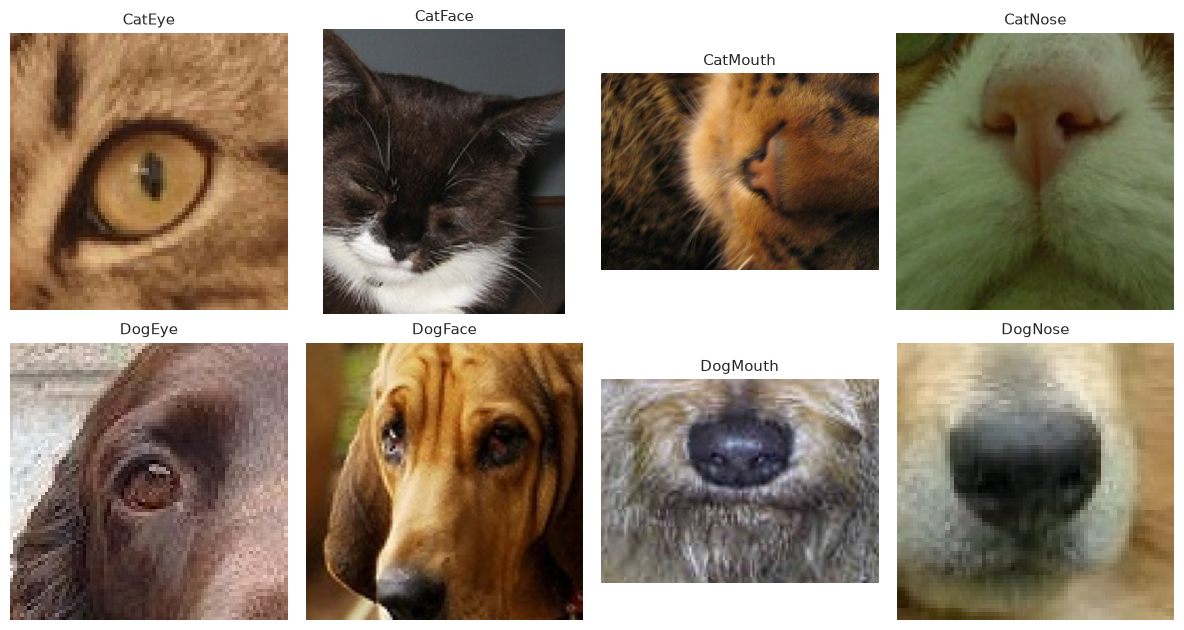

In [5]:
# visualizing a grid of sample images from each class in the training dataset
ids_by_class = labels.groupby("class")["image_id"].apply(list)
grid_layout = [
    ["CatEye", "CatFace", "CatMouth", "CatNose"],
    ["DogEye", "DogFace", "DogMouth", "DogNose"],
]
# setting the random seed for reproducibility and creating a grid of subplots to display sample images from each class
rng = random.Random(CONFIG["seed"])
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for row_axes, row_classes in zip(axes, grid_layout):
    for ax, class_name in zip(row_axes, row_classes):
        ax.imshow(train_archive.open_rgb(rng.choice(ids_by_class[class_name])))
        ax.set_title(class_name, fontsize=11)
        ax.axis("off")
fig.tight_layout()
plt.show()

In [6]:
# COMMIT 2: Leakage-Safe Stratified Split
# Implementation Scope:
# - 80/20 stratified split grouped by file content digest so duplicate images never straddle the split.
# - Per-class balance check and assertions that train and validation share no ids or content.

# defining a function to split the dataset into training and validation sets while ensuring that images with the same content (i.e., same digest) are not split across the two sets
labels = labels.assign(digest=[train_archive.digest(i) for i in labels["image_id"]])

# splitting the dataset into training and validation sets using StratifiedGroupKFold to ensure that the class distribution is maintained and that images with the same content are not split across the two sets
n_splits = round(1 / CONFIG["val_fraction"])
splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=CONFIG["seed"])
train_idx, val_idx = next(splitter.split(labels, labels["class"], groups=labels["digest"]))
train_df = labels.iloc[train_idx].reset_index(drop=True)
val_df = labels.iloc[val_idx].reset_index(drop=True)

# displaying the counts and percentages of each class in the training and validation sets, as well as the imbalance ratio between the majority and minority classes in each set
split_counts = pd.DataFrame({
    "train": train_df["class"].value_counts(),
    "val": val_df["class"].value_counts(),
}).reindex(classes)
split_counts["train_pct"] = split_counts["train"] / split_counts["train"].sum() * 100
split_counts["val_pct"] = split_counts["val"] / split_counts["val"].sum() * 100
print(split_counts.round(2).to_string())

# displaying the counts and percentages of each class in the training and validation sets, as well as the imbalance ratio between the majority and minority classes in each set
for name, frame in (("train", train_df), ("val", val_df)):
    counts = frame["class"].value_counts()
    print(f"{name}: n={len(frame):,} ({len(frame) / len(labels):.1%}) | "
          f"imbalance {counts.max() / counts.min():.3f}:1")
    
# checking for any overlap in image IDs or content (i.e., digest) between the training and validation sets to ensure that there is no data leakage
id_overlap = set(train_df["image_id"]) & set(val_df["image_id"])
content_overlap = set(train_df["digest"]) & set(val_df["digest"])
assert len(train_df) + len(val_df) == len(labels)
assert not id_overlap and not content_overlap
print(f"id overlap: {len(id_overlap)} | content overlap: {len(content_overlap)} | "
      f"duplicate-content images grouped: {int(labels['digest'].duplicated(keep=False).sum())}")

          train   val  train_pct  val_pct
class                                    
CatEye    11107  2777      21.81    21.81
DogEye     9264  2316      18.19    18.19
CatFace    5553  1389      10.90    10.91
DogFace    4632  1158       9.10     9.10
CatMouth   5554  1388      10.91    10.90
DogMouth   4632  1158       9.10     9.10
CatNose    5554  1388      10.91    10.90
DogNose    4632  1158       9.10     9.10
train: n=50,928 (80.0%) | imbalance 2.398:1
val: n=12,732 (20.0%) | imbalance 2.398:1
id overlap: 0 | content overlap: 0 | duplicate-content images grouped: 30


In [7]:
# COMMIT 3: Custom Baseline CNN Architecture
# Implementation Scope:
# - Custom Multi-Layer Convolutional Neural Network built from scratch in PyTorch.
# - Sequential blocks implementing Conv2d, BatchNorm2d, ReLU, and MaxPool2d.
# - Fully connected classification head with Dropout regularization.
# - Structural forward pass verification tracking feature map spatial dimensions.


# defining a function to create a convolutional block with specified input and output channels, consisting of two convolutional layers, each followed by batch normalization and ReLU activation, and a max pooling layer for downsampling
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )

# defining a custom baseline convolutional neural network architecture for pet image classification, consisting of multiple convolutional blocks followed by a fully connected classification head with dropout regularization
class PetBaselineCNN(nn.Module):
    def __init__(self, num_classes, channels=(32, 64, 128, 256), hidden_dim=256, dropout=0.4):
        super().__init__()
        widths = (3,) + tuple(channels)
        self.blocks = nn.ModuleList(
            [conv_block(c_in, c_out) for c_in, c_out in zip(widths[:-1], widths[1:])]
        )
        self.pool = nn.AdaptiveAvgPool2d(1) # defining an adaptive average pooling layer to reduce the spatial dimensions of the feature maps to 1x1 before passing them to the fully connected classification head
        self.classifier = nn.Sequential( # defining a fully connected classification head with dropout regularization
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(channels[-1], hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )
        self.apply(self._init_weights) # applying the weight initialization function to all modules in the network to ensure proper initialization of weights for convolutional and linear layers
    # implementing a static method to initialize the weights of convolutional and linear layers in the network using Kaiming normal and Xavier uniform initialization, respectively
    @staticmethod
    # initialize the weights of convolutional and linear layers
    def _init_weights(module): 
        if isinstance(module, nn.Conv2d):
            nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu") # initializing the weights of convolutional layers using Kaiming normal initialization, which is suitable for layers followed by ReLU activation functions
        elif isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight) # initializing the weights of linear layers using Xavier uniform initialization, which is suitable for layers with linear activation functions
            nn.init.zeros_(module.bias)
    # implementing the forward pass of the network, which defines how input data flows through the convolutional blocks and the fully connected classification head to produce the final output
    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        return self.classifier(self.pool(x))

In [8]:
# testing the forward pass of the PetBaselineCNN model with a random batch of images to verify the output shape and ensure that the model is functioning correctly
model = PetBaselineCNN(CONFIG["num_classes"], dropout=CONFIG["dropout"]).to(CONFIG["device"])
batch = torch.randn(CONFIG["batch_size"], 3, *CONFIG["image_size"], device=CONFIG["device"])

# registering forward hooks on each convolutional block in the model to capture the output shapes of the feature maps during the forward pass for verification and debugging purposes
block_shapes = []
hooks = [block.register_forward_hook(lambda m, inp, out: block_shapes.append(tuple(out.shape))) for block in model.blocks]

# performing a forward pass of the model with the random batch of images while disabling gradient computation to verify the output shape and ensure that the model is functioning correctly
model.eval()
with torch.no_grad():
    logits = model(batch) # performing a forward pass of the model with the random batch of images while disabling gradient computation to verify the output shape and ensure that the model is functioning correctly
for hook in hooks:
    hook.remove() # removing the registered forward hooks from each convolutional block in the model after capturing the output shapes of the feature maps during the forward pass to avoid any potential side effects in future forward passes
# printing the output shapes of the feature maps from each convolutional block in the model to verify that the spatial dimensions are being reduced as expected during the forward pass
for index, shape in enumerate(block_shapes, start=1):
    print(f"block {index}: {shape}")
# verifying that the output shape of the logits from the model matches the expected shape based on the batch size and number of classes, and checking that all values in the logits are finite to ensure that the model is functioning correctly
expected = (CONFIG["batch_size"], CONFIG["num_classes"])
assert tuple(logits.shape) == expected, f"expected {expected}, got {tuple(logits.shape)}"
assert torch.isfinite(logits).all(), "non-finite logits"
# calculating the total number of trainable parameters in the model by summing the number of elements in each parameter tensor that requires gradient computation, and printing the output shape of the logits, the total number of trainable parameters, and the device on which the model is located for verification and debugging purposes
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"logits: {tuple(logits.shape)} | trainable parameters: {trainable:,} | device: {next(model.parameters()).device}")

block 1: (64, 32, 112, 112)
block 2: (64, 64, 56, 56)
block 3: (64, 128, 28, 28)
block 4: (64, 256, 14, 14)
logits: (64, 8) | trainable parameters: 1,241,064 | device: cuda:0


In [9]:

# defining a class to manage the best model checkpoint based on validation loss, allowing for saving and loading the best model weights during training
class BestCheckpoint:
    # initializing the BestCheckpoint class with the specified file path for saving the best model weights, creating the parent directory if it does not exist, and initializing the best loss to infinity
    def __init__(self, path):
        self.path = Path(path)
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self.best_loss = float("inf")
    # defining a method to update the best model checkpoint based on the provided validation loss, saving the model weights if the validation loss is lower than the current best loss, and returning a boolean indicating whether the model was updated
    def update(self, model, val_loss):
        if val_loss >= self.best_loss:
            return False
        self.best_loss = val_loss
        torch.save(model.state_dict(), self.path)
        return True
    # defining a method to load the best model weights from the checkpoint file into the provided model, mapping the weights to the specified device (CPU or GPU) for computation, and returning the updated model
    def load_best(self, model, device):
        model.load_state_dict(torch.load(self.path, map_location=device))
        return model

In [10]:
# updating the configuration dictionary to include the path for saving the best model checkpoint, and creating an instance of the BestCheckpoint class with the specified path
device = CONFIG["device"]
use_cuda = device.type == "cuda"
storage_device = device if use_cuda else torch.device("cpu")
height, width = CONFIG["image_size"]

# defining a function to decode and resize an image from the archive given its image ID and the target size, returning the resized image as a NumPy array
def decode_resized(archive, image_id, size):
    return np.asarray(archive.open_rgb(image_id).resize((size[1], size[0]), Image.Resampling.BILINEAR))

# defining a function to build a pixel cache by decoding and resizing images from the archive, storing them in a memory-mapped NumPy array for efficient access during training and evaluation
def build_pixel_cache(archive, image_ids, size, destination, workers):
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(".tmp.npy")
    cache = np.lib.format.open_memmap(
        temporary, mode="w+", dtype=np.uint8, shape=(len(image_ids), *size, 3)
    )

    def fill(index):
        cache[index] = decode_resized(archive, image_ids[index], size)

    with ThreadPoolExecutor(max_workers=workers) as pool:
        list(pool.map(fill, range(len(image_ids))))
    cache.flush()
    del cache
    temporary.replace(destination)

# creating a list of all image IDs from the labels DataFrame and defining the path for the pixel cache file based on the target image size
all_ids = list(labels["image_id"])
cache_path = CONFIG["cache_dir"] / f"train_{height}x{width}.npy"

# checking if the pixel cache file exists, and if not, building the pixel cache by decoding and resizing images from the archive, storing them in a memory-mapped NumPy array for efficient access during training and evaluation
if not cache_path.exists():
    started = time.time()
    build_pixel_cache(
        train_archive, all_ids, CONFIG["image_size"], cache_path, min(os.cpu_count() or 4, 32)
    )
    print(f"pixel cache built in {time.time() - started:.0f}s")

# loading the pixel cache from the specified path using memory mapping for efficient access, and asserting that the shape of the cache matches the expected dimensions based on the number of images and target image size
cache = np.load(cache_path, mmap_mode="r")
assert cache.shape == (len(all_ids), height, width, 3), "cache is stale; delete it and rebuild"
row_of_id = {image_id: row for row, image_id in enumerate(all_ids)}

# defining a function to load a split of the dataset (training or validation) by retrieving the corresponding images and targets from the pixel cache and labels DataFrame, converting them to PyTorch tensors, and moving them to the specified storage device (CPU or GPU)
def load_split(frame):
    rows = np.array([row_of_id[i] for i in frame["image_id"]])
    images = torch.from_numpy(cache[rows]).to(storage_device)
    targets = torch.tensor(frame["class"].map(class_to_idx).to_numpy(), dtype=torch.long, device=storage_device)
    return images, targets

# loading the training and validation splits of the dataset by retrieving the corresponding images and targets from the pixel cache and labels DataFrame, converting them to PyTorch tensors, and moving them to the specified storage device (CPU or GPU)
train_x, train_y = load_split(train_df)
val_x, val_y = load_split(val_df)
print(f"pixels loaded to {storage_device}")

norm_mean = torch.tensor(CONFIG["imagenet_mean"], device=device).view(1, 3, 1, 1)
norm_std = torch.tensor(CONFIG["imagenet_std"], device=device).view(1, 3, 1, 1)

# defining a function to perform data augmentation on a batch of images, including random horizontal flipping, rotation, brightness adjustment, and color jittering, while ensuring that the augmented images remain within valid pixel value ranges
def augment_batch(batch, max_degrees=15.0, jitter=0.2):
    n = batch.size(0)

    def factor():
        return 1 + (torch.rand(n, 1, 1, 1, device=batch.device) * 2 - 1) * jitter

    flip = torch.rand(n, device=batch.device) < 0.5
    batch = torch.where(flip.view(-1, 1, 1, 1), batch.flip(3), batch)

    angles = (torch.rand(n, device=batch.device) * 2 - 1) * max_degrees * math.pi / 180
    cos, sin, zeros = angles.cos(), angles.sin(), torch.zeros(n, device=batch.device)
    theta = torch.stack(
        (torch.stack((cos, -sin, zeros), dim=1), torch.stack((sin, cos, zeros), dim=1)), dim=1
    )
    grid = F.affine_grid(theta, batch.shape, align_corners=False)
    batch = F.grid_sample(batch, grid, mode="bilinear", padding_mode="reflection", align_corners=False)

    batch = (batch * factor()).clamp(0, 1)
    gray = batch[:, 0:1] * 0.299 + batch[:, 1:2] * 0.587 + batch[:, 2:3] * 0.114
    mean = gray.mean(dim=(1, 2, 3), keepdim=True)
    batch = ((batch - mean) * factor() + mean).clamp(0, 1)
    gray = batch[:, 0:1] * 0.299 + batch[:, 1:2] * 0.587 + batch[:, 2:3] * 0.114
    return ((batch - gray) * factor() + gray).clamp(0, 1)

# defining a custom data loader class to load images and targets from memory, with options for batching, shuffling, data augmentation, and dropping the last incomplete batch
class InMemoryLoader:
    def __init__(self, images, targets, batch_size, shuffle, augment=False, drop_last=False, seed=0):
        self.images, self.targets = images, targets
        self.batch_size, self.shuffle = batch_size, shuffle
        self.augment, self.drop_last = augment, drop_last
        self.generator = torch.Generator().manual_seed(seed)

    # defining the length of the InMemoryLoader object as the number of batches, calculated based on the total number of images and the specified batch size, with an option to drop the last incomplete batch if specified
    def __len__(self):
        count = self.images.size(0)
        return count // self.batch_size if self.drop_last else math.ceil(count / self.batch_size)
    
    # defining the iterator for the InMemoryLoader object, which yields batches of images and targets, with options for shuffling, data augmentation, and normalization
    def __iter__(self):
        count = self.images.size(0)
        order = torch.randperm(count, generator=self.generator) if self.shuffle else torch.arange(count)
        order = order.to(self.images.device)
        for step in range(len(self)):
            index = order[step * self.batch_size:(step + 1) * self.batch_size]
            batch = self.images[index].to(device, non_blocking=True).permute(0, 3, 1, 2).float().div_(255)
            if self.augment:
                batch = augment_batch(batch)
            batch = ((batch - norm_mean) / norm_std).contiguous(memory_format=torch.channels_last)
            yield batch, self.targets[index].to(device, non_blocking=True)

# setting up the training and validation data loaders using the InMemoryLoader class, with specified batch sizes, shuffling, data augmentation for the training loader, and dropping the last incomplete batch for the training loader
train_loader = InMemoryLoader(
    train_x, train_y, CONFIG["train_batch_size"], shuffle=True, augment=True,
    drop_last=True, seed=CONFIG["seed"],
)
# setting up the validation data loader using the InMemoryLoader class, with specified batch size and no shuffling or data augmentation
val_loader = InMemoryLoader(val_x, val_y, CONFIG["eval_batch_size"], shuffle=False)

# printing the device being used for computation, the number of training and validation images and batches, and the total number of pixels in the training images along with their size in gigabytes
print(f"device: {device} | train: {len(train_x):,} images, {len(train_loader)} batches | "
      f"val: {len(val_x):,} images, {len(val_loader)} batches | "
      f"pixels on {train_x.device}, {train_x.numel() / 1e9:.1f} GB")
print("data pipeline ready: train_loader and val_loader are defined")

pixel cache built in 146s
pixels loaded to cuda
device: cuda | train: 50,928 images, 198 batches | val: 12,732 images, 13 batches | pixels on cuda:0, 7.7 GB
data pipeline ready: train_loader and val_loader are defined


In [ ]:
# defining a function to run a single pass of training or evaluation on the provided model using the specified data loader, loss criterion, and optimizer (if training), returning the average loss and accuracy for the pass
def run_pass(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device, dtype=torch.long)
    seen = 0
    # running the pass with gradient computation enabled if training, and using mixed precision for faster computation on supported devices
    with torch.set_grad_enabled(training):
        for images, targets in loader:
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_cuda):
                logits = model(images)
            loss = criterion(logits.float(), targets)
            # if training, zero the gradients, perform backpropagation, and update the model parameters using the optimizer
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            # accumulating the total loss, number of correct predictions, and number of samples seen for calculating the average loss and accuracy at the end of the pass
            loss_sum += loss.detach() * targets.size(0)
            correct += (logits.argmax(dim=1) == targets).sum()
            seen += targets.size(0)
    # returning the average loss and accuracy for the pass by dividing the accumulated loss and correct predictions by the total number of samples seen
    return loss_sum.item() / seen, correct.item() / seen

# defining a function to fit the provided model using the specified number of epochs, learning rate, and weight decay, while logging the training and validation loss and accuracy, saving the best model checkpoint based on validation loss, and returning the training history
def fit_model(model, name, epochs, learning_rate, weight_decay=None):
    weight_decay = CONFIG["weight_decay"] if weight_decay is None else weight_decay
    seed_everything(CONFIG["seed"])
    if use_cuda:
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    train_loader.generator.manual_seed(CONFIG["seed"]) # setting the random seed for the training data loader's generator to ensure reproducibility of the data shuffling and augmentation during training

    # moving the model to the specified device (CPU or GPU) for computation, and if using CUDA, setting the memory format to channels last for better performance on supported GPUs
    model = model.to(device)
    if use_cuda:
        model = model.to(memory_format=torch.channels_last)
    trainable = [p for p in model.parameters() if p.requires_grad]
    frozen_count = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    print(f"{name} | trainable {sum(p.numel() for p in trainable):,} | frozen {frozen_count:,}")

    # setting up the loss criterion, optimizer, learning rate scheduler, and best checkpoint manager for training the model
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(trainable, lr=learning_rate, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=CONFIG["eta_min"]
    )
    checkpoint = BestCheckpoint(CONFIG["checkpoint_dir"] / f"{name}.pt") # creating an instance of the BestCheckpoint class to manage the best model checkpoint based on validation loss, saving the best model weights to the specified file path during training

    # initializing a dictionary to store the training and validation loss, accuracy, and learning rate history for each epoch, creating the parent directory for the history CSV file if it does not exist, and recording the start time of the training run
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
    history_path = CONFIG["history_dir"] / f"{name}_history.csv"
    history_path.parent.mkdir(parents=True, exist_ok=True)
    run_started = time.time()

    # running the training loop for the specified number of epochs, performing a training pass and a validation pass for each epoch, updating the learning rate scheduler, saving the training history to a CSV file, and managing the best model checkpoint based on validation loss
    for epoch in range(1, epochs + 1):
        epoch_started = time.time()
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc = run_pass(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_pass(model, val_loader, criterion)
        scheduler.step()

        # saving the training and validation loss, accuracy, and learning rate for the current epoch to the history dictionary and writing it to a CSV file for later analysis
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(lr)
        pd.DataFrame(history).to_csv(history_path, index=False)

        # checking if the current validation loss is lower than the best validation loss seen so far, and if so, saving the model weights to the checkpoint file and indicating that the model was improved
        improved = checkpoint.update(model, val_loss)
        elapsed = time.time() - epoch_started
        print(
            f"epoch {epoch:02d}/{epochs} | lr {lr:.2e} | "
            f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
            f"val loss {val_loss:.4f} acc {val_acc:.4f} | "
            f"{elapsed:.0f}s ({len(train_x) / elapsed:,.0f} img/s){' | saved' if improved else ''}"
        )
    # after training is complete, determining the epoch with the best validation loss, loading the best model weights from the checkpoint file, running a final validation pass to obtain the best loss and accuracy, and printing the total training time, best epoch, validation loss, and accuracy
    best_epoch = int(np.argmin(history["val_loss"])) + 1
    checkpoint.load_best(model, device)
    best_loss, best_acc = run_pass(model, val_loader, criterion)
    print(f"total {(time.time() - run_started) / 60:.1f} min | best epoch {best_epoch} | "
          f"val loss {best_loss:.4f} | val accuracy {best_acc:.4f}\n")
    return history

In [12]:
# smoke test: single-batch training loop to verify that the model, optimizer, and loss function are functioning correctly before proceeding with full training
device = CONFIG["device"]
use_cuda = device.type == "cuda"
height, width = CONFIG["image_size"]

# running a smoke test by sampling a small batch of images and labels from the training dataset, preprocessing them, and performing a single-batch training loop to verify that the model, optimizer, and loss function are functioning correctly
smoke_frame = train_df.sample(16, random_state=CONFIG["seed"])
smoke_pixels = np.stack([
    np.asarray(train_archive.open_rgb(i).resize((width, height), Image.Resampling.BILINEAR))
    for i in smoke_frame["image_id"]
])
# normalizing the sampled images using the ImageNet mean and standard deviation, converting them to PyTorch tensors, and moving them to the specified device (CPU or GPU) for computation
smoke_mean = torch.tensor(CONFIG["imagenet_mean"]).view(1, 3, 1, 1)
smoke_std = torch.tensor(CONFIG["imagenet_std"]).view(1, 3, 1, 1)
fixed_images = torch.from_numpy(smoke_pixels).permute(0, 3, 1, 2).float().div(255)
fixed_images = ((fixed_images - smoke_mean) / smoke_std).to(device)
fixed_targets = torch.tensor(
    smoke_frame["class"].map(class_to_idx).to_numpy(), dtype=torch.long, device=device
)
# defining the model, optimizer, and loss function for the smoke test, moving the model to the specified device (CPU or GPU) for computation, and setting it to training mode
smoke_model = PetBaselineCNN(CONFIG["num_classes"], dropout=CONFIG["dropout"]).to(device)
smoke_optimizer = torch.optim.AdamW(smoke_model.parameters(), lr=1e-3, weight_decay=CONFIG["weight_decay"])
smoke_criterion = nn.CrossEntropyLoss()

# running the single-batch training loop for a specified number of iterations, performing forward and backward passes, updating the model parameters using the optimizer, and recording the loss for each iteration to verify that the model, optimizer, and loss function are functioning correctly
smoke_model.train()
smoke_losses = []
for _ in range(15):
    smoke_optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_cuda):
        smoke_logits = smoke_model(fixed_images)
    smoke_loss = smoke_criterion(smoke_logits.float(), fixed_targets)
    smoke_loss.backward()
    smoke_optimizer.step()
    smoke_losses.append(smoke_loss.item())
# verifying that all recorded losses in the single-batch training loop are finite to ensure that the model, optimizer, and loss function are functioning correctly
assert all(np.isfinite(smoke_losses)), "non-finite loss in single-batch loop"
print(f"reference ln({CONFIG['num_classes']}) = {np.log(CONFIG['num_classes']):.4f} | "
      f"single-batch loop: {smoke_losses[0]:.4f} -> {smoke_losses[-1]:.4f}")

# saving the best model checkpoint from the single-batch training loop, loading it into a new instance of the PetBaselineCNN model, and verifying that the checkpoint round-trip was successful by deleting the original model, optimizer, and restored model
smoke_checkpoint = BestCheckpoint(CONFIG["checkpoint_dir"] / "smoke_test.pt")
smoke_checkpoint.update(smoke_model, smoke_losses[-1])
restored = PetBaselineCNN(CONFIG["num_classes"], dropout=CONFIG["dropout"]).to(device) # creating a new instance of the PetBaselineCNN model with the same architecture and moving it to the specified device (CPU or GPU) for computation
smoke_checkpoint.load_best(restored, device)
smoke_checkpoint.path.unlink()
print("checkpoint round-trip verified")
del smoke_model, smoke_optimizer, restored # deleting the original model, optimizer, and restored model instances to free up memory after verifying that the checkpoint round-trip was successful

reference ln(8) = 2.0794 | single-batch loop: 3.1999 -> 0.2589
checkpoint round-trip verified


In [13]:
# COMMIT 5: Baseline CNN Training and Evaluation
# Implementation Scope:
# - 10 epochs of AdamW with cosine annealing over the full 50,928-image training split.
# - Validation on the full 12,732-image held-out split after every epoch.
# - Per-epoch history written to CSV and best-validation-loss weights restored at the end.

# checking that all required variables and functions are defined in the global scope before proceeding with training the baseline CNN model
required = ("train_loader", "val_loader", "train_x", "fit_model", "PetBaselineCNN", "BestCheckpoint")
missing = [name for name in required if name not in globals()]
assert not missing, f"missing {missing}: run the pixel cache and GPU loaders cell and the training engine cell first"

# training the baseline CNN model using the fit_model function with the specified number of epochs and learning rate, and storing the training history for later analysis
baseline_model = PetBaselineCNN(CONFIG["num_classes"], dropout=CONFIG["dropout"])
baseline_history = fit_model(baseline_model, "baseline_cnn", epochs=10, learning_rate=1e-3)

baseline_cnn | trainable 1,241,064 | frozen 0
epoch 01/10 | lr 1.00e-03 | train loss 1.5862 acc 0.3949 | val loss 1.0835 acc 0.5975 | 146s (348 img/s) | saved
epoch 02/10 | lr 9.76e-04 | train loss 0.8908 acc 0.6769 | val loss 0.5818 acc 0.7869 | 92s (556 img/s) | saved
epoch 03/10 | lr 9.05e-04 | train loss 0.5994 acc 0.7903 | val loss 0.6422 acc 0.7806 | 92s (556 img/s)
epoch 04/10 | lr 7.94e-04 | train loss 0.4638 acc 0.8396 | val loss 0.6531 acc 0.7808 | 92s (556 img/s)
epoch 05/10 | lr 6.55e-04 | train loss 0.3735 acc 0.8714 | val loss 0.3419 acc 0.8763 | 92s (556 img/s) | saved
epoch 06/10 | lr 5.01e-04 | train loss 0.3065 acc 0.8956 | val loss 0.2928 acc 0.8986 | 92s (556 img/s) | saved
epoch 07/10 | lr 3.46e-04 | train loss 0.2607 acc 0.9120 | val loss 0.4449 acc 0.8758 | 92s (556 img/s)
epoch 08/10 | lr 2.07e-04 | train loss 0.2234 acc 0.9251 | val loss 0.3554 acc 0.8783 | 92s (556 img/s)
epoch 09/10 | lr 9.64e-05 | train loss 0.1989 acc 0.9336 | val loss 0.1316 acc 0.9529 | 9

In [ ]:
# loading the training history for the baseline CNN model from the CSV file, determining the epoch with the best validation loss, loading the best model weights from the checkpoint file, running a final validation pass to obtain the best loss and accuracy, and printing the number of epochs run, best epoch, validation loss, and accuracy
baseline_history = pd.read_csv(CONFIG["history_dir"] / "baseline_cnn_history.csv").to_dict(orient="list")
best_epoch = int(np.argmin(baseline_history["val_loss"])) + 1

# loading the best model weights from the checkpoint file for the baseline CNN model and running a final validation pass to obtain the best loss and accuracy
BestCheckpoint(CONFIG["checkpoint_dir"] / "baseline_cnn.pt").load_best(baseline_model, device)
best_loss, best_acc = run_pass(baseline_model, val_loader, nn.CrossEntropyLoss())
print(f"epochs run: {len(baseline_history['val_loss'])} | best epoch {best_epoch} | "
      f"val loss {best_loss:.4f} | val accuracy {best_acc:.4f}")

epochs run: 10 | best epoch 10 | val loss 0.1179 | val accuracy 0.9593


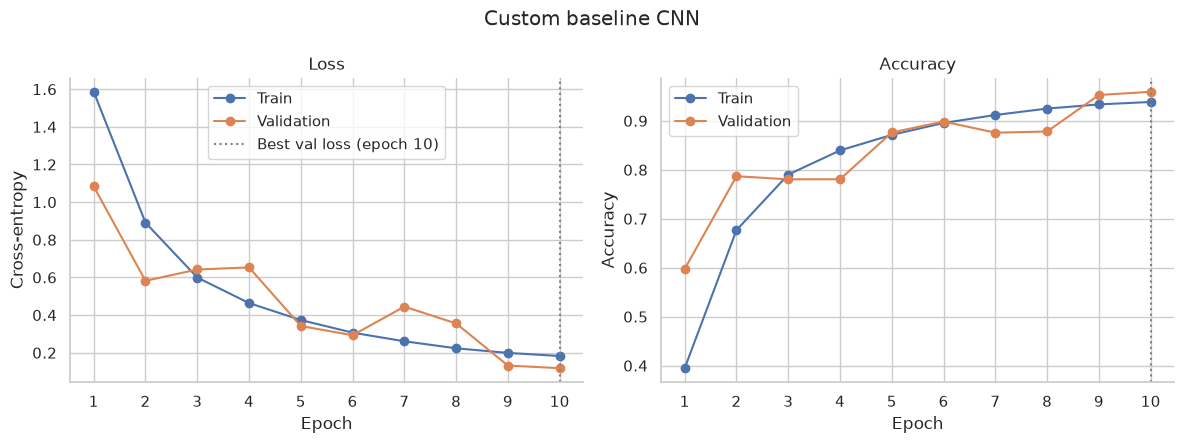

In [16]:
# defining a function to plot the training and validation loss and accuracy history for the model, highlighting the epoch with the best validation loss, and displaying the plots using Matplotlib and Seaborn
def plot_history(history, title):
    epoch_axis = np.arange(1, len(history["train_loss"]) + 1)
    best_epoch = int(np.argmin(history["val_loss"])) + 1

    fig, (loss_ax, acc_ax) = plt.subplots(1, 2, figsize=(12, 4.5))

    # plotting the training and validation loss history on the left subplot, marking the epoch with the best validation loss with a vertical line, and setting the title, labels, and legend for the loss plot
    loss_ax.plot(epoch_axis, history["train_loss"], marker="o", label="Train")
    loss_ax.plot(epoch_axis, history["val_loss"], marker="o", label="Validation")
    loss_ax.axvline(best_epoch, color="gray", linestyle=":", label=f"Best val loss (epoch {best_epoch})")
    loss_ax.set_title("Loss")
    loss_ax.set_xlabel("Epoch")
    loss_ax.set_ylabel("Cross-entropy")
    loss_ax.legend()

    # plotting the training and validation accuracy history on the right subplot, marking the epoch with the best validation accuracy with a vertical line, and setting the title, labels, and legend for the accuracy plot
    acc_ax.plot(epoch_axis, history["train_acc"], marker="o", label="Train")
    acc_ax.plot(epoch_axis, history["val_acc"], marker="o", label="Validation")
    acc_ax.axvline(best_epoch, color="gray", linestyle=":")
    acc_ax.set_title("Accuracy")
    acc_ax.set_xlabel("Epoch")
    acc_ax.set_ylabel("Accuracy")
    acc_ax.legend()

    # setting the x-ticks for both subplots to correspond to the epoch numbers, removing the top and right spines from the plots for a cleaner appearance, setting the overall title for the figure, adjusting the layout to prevent overlap, and displaying the plots
    for ax in (loss_ax, acc_ax):
        ax.set_xticks(epoch_axis)
        sns.despine(ax=ax)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

# plotting the training and validation loss and accuracy history for the baseline convolutional neural network model using the plot_history function, with the title "Custom baseline CNN"
plot_history(baseline_history, "Custom baseline CNN")